#### Task 2: Scatter plot of Myntra ad spend (lakhs) vs app downloads with the line of best fit.

 ad_spend_lakhs  app_downloads
              5          38000
              8          42000
             12          61000
             15          63000
             20          82000
             24          88000
             28         108000
             33         112000
             38         135000
             45         150000 

Line of best fit: downloads = 2,861 x ad_spend + 22,665
Correlation r = 0.995


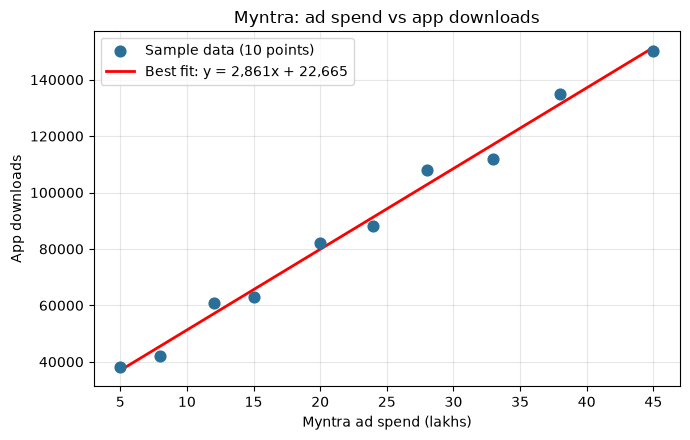

Plot saved to myntra_scatter.png


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib
if "__file__" in globals():            # plain script: save to file; notebook: show inline
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
 
HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
 
# 10 sample data points (illustrative)
myntra = pd.DataFrame({
    "ad_spend_lakhs": [5, 8, 12, 15, 20, 24, 28, 33, 38, 45],
    "app_downloads":  [38000, 42000, 61000, 63000, 82000, 88000, 108000, 112000, 135000, 150000],
})
myntra.to_csv(os.path.join(HERE, "myntra_ads.csv"), index=False)
print(myntra.to_string(index=False), "\n")
 
x, y = myntra["ad_spend_lakhs"], myntra["app_downloads"]
slope, intercept = np.polyfit(x, y, 1)                 # least-squares line y = slope * x + intercept
print(f"Line of best fit: downloads = {slope:,.0f} x ad_spend + {intercept:,.0f}")
print(f"Correlation r = {x.corr(y):.3f}")
 
plt.figure(figsize=(7, 4.5))
plt.scatter(x, y, color="#2a6f97", s=60, label="Sample data (10 points)", zorder=3)
xs = np.linspace(x.min(), x.max(), 100)
plt.plot(xs, slope * xs + intercept, color="red", lw=2, label=f"Best fit: y = {slope:,.0f}x + {intercept:,.0f}")
plt.xlabel("Myntra ad spend (lakhs)")
plt.ylabel("App downloads")
plt.title("Myntra: ad spend vs app downloads")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(HERE, "myntra_scatter.png"), dpi=150)
if "__file__" not in globals():
    plt.show()
print("Plot saved to myntra_scatter.png")